# Sunstars: diffraction at the iris of a camera lens

Stop a wide angle lens down to f/16, point it at the Sun or at a street
lamp, and the bright source turns into a star with sharp rays. Photographers
call it a sunstar, and lenses are known by it: a lens with seven blades gives
fourteen rays, one with eight blades gives eight, and some modern lenses with
rounded blades give soft stars or none at all when used wide open.

The star is the Fraunhofer diffraction pattern of the iris opening. A
distant point source sends a plane wave into the lens. In the focal plane
the field is the Fourier transform of the opening, and the image of the
point is its squared magnitude. For a round opening that is the Airy
pattern. For a polygon each straight edge sends a streak perpendicular to
itself.

This notebook covers:

1. the diffraction pattern of an iris, computed both from an FFT of the
   sampled opening and as an exact sum over its edges,
2. why a straight edge makes a spike, and why an iris with n blades has
   2n spikes for odd n but n for even n, together with how bright a spike
   is along and across it, and why spikes take no light away from the core,
3. rounded blades, which turn each spike into a fan that fades faster,
4. the F-number: how long the rays of the Sun are, and why they grow when
   the lens is stopped down,
5. rendered sunstars in colour: the Sun through a 24 mm lens with straight
   and rounded blades.

Notebook 90 covered the out-of-focus image of the same kind of lens
(bokeh). Here the source is in focus and the iris alone shapes the
pattern. Aberrations and flare are left out.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
from scipy.signal import find_peaks
from scipy.special import j0, j1

from pyoptics import colour
from pyoptics import photography as ph
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
A = np.pi        # all openings in sections 1 to 3 have the area of the unit circle

## 1. The diffraction pattern of an iris

A lens of focal length $f$ that is focused on a distant point produces the
far field of its pupil in the focal plane. The amplitude at a point $\mathbf r$
is the Fourier transform of the opening (the pupil function $P$, here 1
inside the iris and 0 outside):

$$U(\mathbf r) \propto F(\mathbf k) = \int_{\rm opening} e^{-i\mathbf k\cdot\boldsymbol\xi}\,d^2\xi, \qquad \mathbf k = \frac{2\pi}{\lambda f}\,\mathbf r .$$

For a polygon this integral has a closed form. Since
$e^{-i\mathbf k\cdot\boldsymbol\xi} = \nabla\cdot\big(i\mathbf k\,e^{-i\mathbf k\cdot\boldsymbol\xi}/k^2\big)$,
Gauss' theorem turns the area integral into a sum over the edges. Edge $j$
has the vector $\mathbf e_j$, the outward normal times its length
$\mathbf N_j = (e_y, -e_x)$ and the midpoint $\mathbf m_j$, and

$$F(\mathbf k) = \frac{i}{k^2}\sum_j (\mathbf k\cdot\mathbf N_j)\, e^{-i\mathbf k\cdot\mathbf m_j}\,\mathrm{sinc}\!\left(\tfrac{\mathbf k\cdot\mathbf e_j}{2}\right)$$

(`ph.polygon_transform()`, after Lee and Mittra). An iris with $n$ straight
blades leaves a regular $n$-gon (`ph.iris()`). Camera lenses set their
F-numbers by the area of the opening, so an f/N stop is a polygon with the
area of a circle of diameter $f/N$ (`ph.iris_apothem()`).

In the plots below every opening has the area of the unit circle, so that
$D = 2$ and distances in the focal plane are $r/\lambda N = k/\pi$.

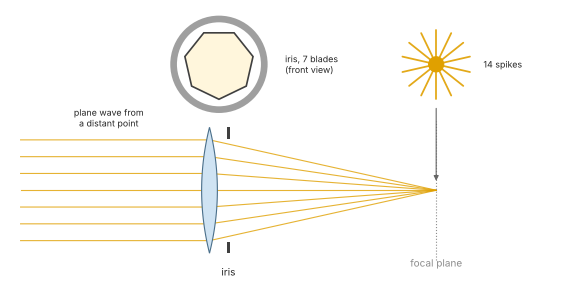

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.6))
sketch.iris_diffraction(ax)
plt.show()

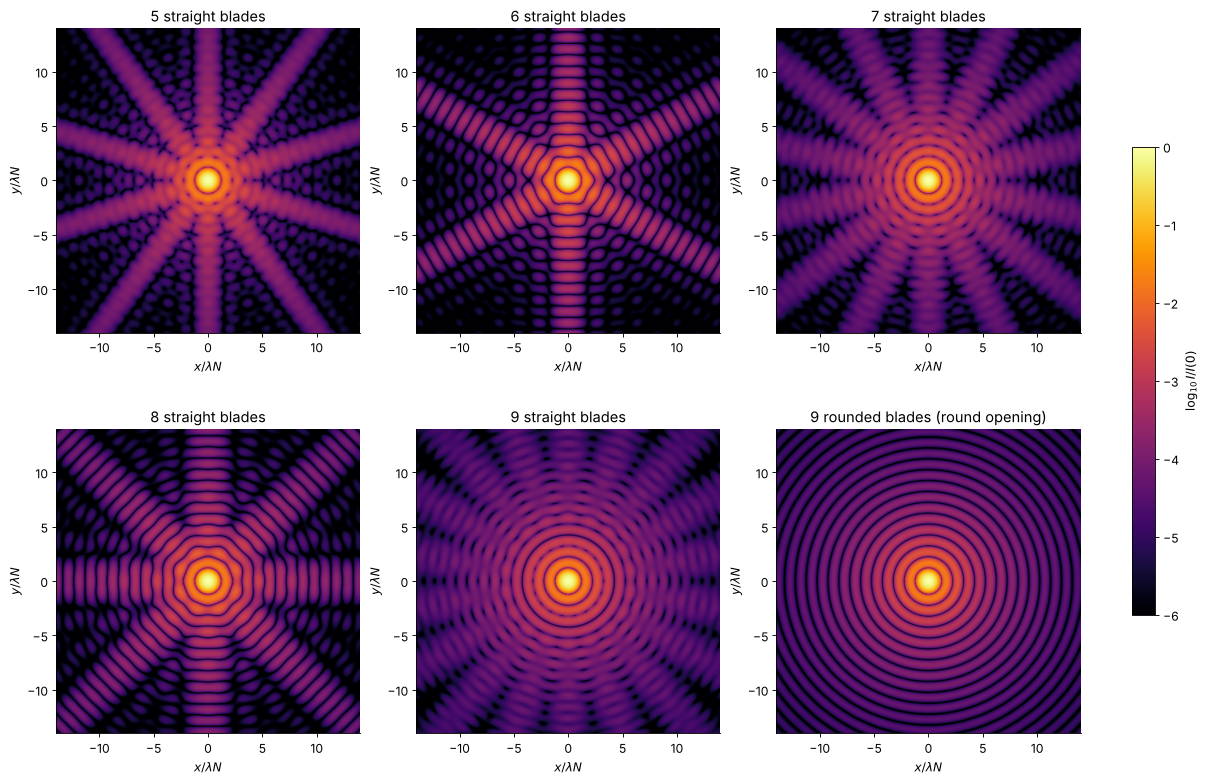

In [3]:
# far field patterns: straight blades 5 to 9, and 9 rounded blades at the opening they are made for
cases = [(5, np.inf), (6, np.inf), (7, np.inf), (8, np.inf), (9, np.inf), (9, "round")]
psfs = {}
for n_b, rho in cases:
    if rho == "round":
        h, r_b = 1.0, 1.0                          # h = rho: the opening is a circle
    else:
        h, r_b = ph.iris_apothem(n_b, A), np.inf
    k, I = ph.iris_psf(n_b, h, r_b, rotation=np.pi/2, n=2048, dx=np.pi/160)
    psfs[(n_b, rho)] = I

fig, ax = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")
ext = np.array([k[0], k[-1], k[0], k[-1]])/np.pi        # r in units of lambda N
for a, (key, I) in zip(ax.ravel(), psfs.items()):
    im = a.imshow(np.log10(I + 1e-12), extent=ext, origin="lower", vmin=-6, vmax=0, cmap="inferno")
    a.set_xlim(-14, 14); a.set_ylim(-14, 14)
    n_b, rho = key
    a.set_title("{} {} blades{}".format(n_b, "straight" if rho != "round" else "rounded",
                                        "" if rho != "round" else " (round opening)"))
    a.set_xlabel(r"$x/\lambda N$"); a.set_ylabel(r"$y/\lambda N$")
fig.colorbar(im, ax=ax, shrink=0.6, label=r"$\log_{10} I/I(0)$")
plt.show()

Every pattern has the bright core of the Airy pattern, about $1.2\,\lambda N$
in radius, because the core only depends on the area. Further out the
patterns differ. The round opening gives rings. The polygons give rays:
10 for five blades, 6 for six, 14 for seven, 8 for eight and 18 for nine.
The rays of an even polygon carry fringes, and those of an odd polygon are
smooth. Section 2 explains both.

These patterns come from `ph.iris_psf()`, the FFT of the sampled opening.
Its edges are antialiased (`ph.iris_coverage()`, from the signed distance
to the edges), and the box this puts across each edge is divided out. Along
a spike the FFT agrees with the exact sum over the edges:

In [4]:
# FFT of the sampled opening vs the exact transform (sum over the edges), along a spike
n_b = 7
h = ph.iris_apothem(n_b, A)
k, I = ph.iris_psf(n_b, h, n=2048, dx=np.pi/160)
v = ph.iris(n_b, h)
c = len(k)//2
print("  k      r/(lambda N)   FFT I/I(0)      exact I/I(0)     ratio")
for kk in (5, 10, 20, 40, 80):
    i = c + int(round(kk/(k[1] - k[0])))
    exact = abs(ph.polygon_transform(v, k[i], 0.0)/A)**2
    print("{:5.1f}   {:8.2f}      {:12.4e}    {:12.4e}    {:.3f}".format(k[i], k[i]/np.pi, I[c, i], exact,
                                                                    I[c, i]/exact))

  k      r/(lambda N)   FFT I/I(0)      exact I/I(0)     ratio
  5.0       1.59        1.6754e-02      1.6767e-02    0.999
 10.0       3.18        3.5950e-04      3.5999e-04    0.999
 20.0       6.37        3.5546e-04      3.5695e-04    0.996
 40.0      12.73        6.1153e-05      6.3484e-05    0.963
 80.0      25.46        1.1667e-05      1.3804e-05    0.845


The two agree to better than 4 % up to a quarter of the sampling limit
$\pi/dx = 160$. Towards the limit the FFT falls low because the edge waves
alias. The renders in section 5 stay inside that range.

Now count the rays of the exact transform, from the maxima of the angular
profile at a large $k$, for 3 to 12 blades:

In [5]:
# count the spikes: angular profile of the exact transform, averaged over a band of k
th = np.linspace(0, 2*np.pi, 7200, endpoint=False)
kb = np.linspace(60, 90, 31)[:, None]
counts = {}
for n_b in range(3, 13):
    v = ph.iris(n_b, ph.iris_apothem(n_b, A), rotation=0.1)
    prof = np.mean(abs(ph.polygon_transform(v, kb*np.cos(th), kb*np.sin(th))/A)**2, axis=0)
    prof = np.roll(prof, -np.argmin(prof))          # start at a minimum (the profile is periodic)
    peaks, _ = find_peaks(prof, prominence=0.3*prof.max())
    counts[n_b] = len(peaks)
print("blades:        ", " ".join("{:3d}".format(n) for n in counts))
print("spikes found:  ", " ".join("{:3d}".format(c) for c in counts.values()))
print("2n (odd), n (even):", " ".join("{:3d}".format(ph.spike_count(n)) for n in counts))

blades:           3   4   5   6   7   8   9  10  11  12
spikes found:     6   4  10   6  14   8  18  10  22  12
2n (odd), n (even):   6   4  10   6  14   8  18  10  22  12


## 2. One spike per edge, both ways

The edge formula explains the rays. Look along the normal of edge $j$
($\mathbf k \parallel \mathbf N_j$). There $\mathbf k\cdot\mathbf e_j = 0$,
so the sinc is 1, and the edge contributes an amplitude
$|\mathbf k\cdot\mathbf N_j|/k^2 = L/k$ that falls off only as $1/k$. In any
other direction the sinc makes it fall as $1/k^2$. Each straight edge
therefore sends a streak along its normal, and the streak goes both ways:
the far field of a real opening is centrosymmetric, $|F(-\mathbf k)| = |F(\mathbf k)|$.

- For an **odd** number of blades no two edges are parallel. The $n$ edges
  give $n$ streaks in each direction, which makes **2n spikes**.
- For an **even** number, opposite edges are parallel. Their streaks fall
  on top of each other, which makes **n spikes**, each from two edges a
  distance $2h$ apart. The two edges interfere, so the spike has fringes,
  $4\sin^2(kh)\,(L/kA)^2$, and is on average twice as bright as the spike
  of a single edge.

That is the counting rule found above: 2n spikes for odd n, n for even n
(`ph.spike_count()`). Telescope spiders follow the same rule: three vanes
make six spikes and four vanes make four.

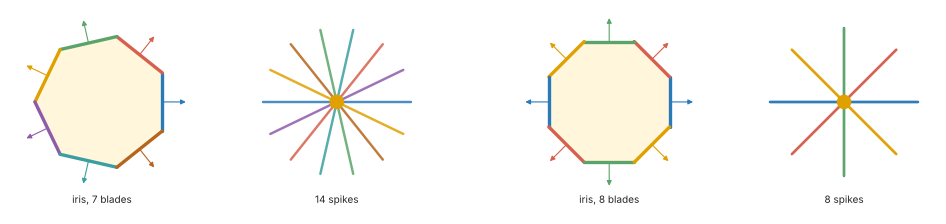

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
sketch.iris_spikes(ax[0], 7)
sketch.iris_spikes(ax[1], 8)
plt.show()

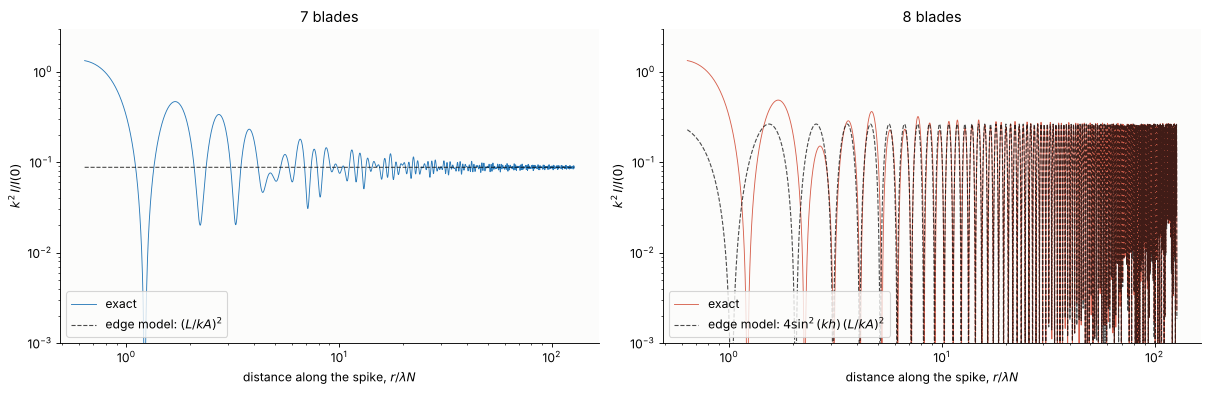

7 blades: mean k^2 I = 0.0900, edge model 0.0876 (L^2/A^2)
8 blades: mean k^2 I = 0.1333, edge model 0.1318 (2 L^2/A^2)


In [7]:
# along a spike: odd (7) and even (8) number of blades
kk = np.geomspace(2, 400, 3000)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for a, n_b, col in ((ax[0], 7, BLUE), (ax[1], 8, RED)):
    h = ph.iris_apothem(n_b, A)
    v = ph.iris(n_b, h)
    L = ph.iris_edge_length(n_b, h)
    I = abs(ph.polygon_transform(v, kk, 0*kk)/A)**2           # the edge with normal along +x
    n_par = 2 if n_b % 2 == 0 else 1
    model = ph.edge_spike(kk, L, A, n_par, 2*h)
    a.loglog(kk/np.pi, I*kk**2, color=col, lw=0.8, label="exact")
    a.loglog(kk/np.pi, model*kk**2, color="k", lw=1.0, ls="--", alpha=0.7,
             label="edge model" + (r": $4\sin^2(kh)\,(L/kA)^2$" if n_par == 2 else r": $(L/kA)^2$"))
    a.set_xlabel(r"distance along the spike, $r/\lambda N$"); a.set_ylabel(r"$k^2\,I/I(0)$")
    a.set_title("{} blades".format(n_b)); a.set_ylim(1e-3, 3); a.legend(loc="lower left")
plt.show()
# band averages, k = 20 ... 400
for n_b in (7, 8):
    h = ph.iris_apothem(n_b, A); v = ph.iris(n_b, h); L = ph.iris_edge_length(n_b, h)
    sel = kk > 20
    I = abs(ph.polygon_transform(v, kk[sel], 0*kk[sel])/A)**2
    print("{} blades: mean k^2 I = {:.4f}, edge model {:.4f} ({}L^2/A^2)".format(
        n_b, np.mean(I*kk[sel]**2), (2 if n_b % 2 == 0 else 1)*L**2/A**2, "2 " if n_b % 2 == 0 else ""))

Multiplied by $k^2$, the exact intensity along the spike settles onto the
edge model within a few multiples of $\lambda N$ from the centre. For seven
blades it is the flat $(L/A)^2$; for eight blades it is the fringes of two
parallel edges, averaging $2(L/A)^2$. A spike is a $1/r^2$ tail. The Airy
rings of a round opening fall as $1/r^3$, so the polygon's spikes outlast
them.

Across the spike, the streak has the profile of the slit diffraction of the
edge length, $\mathrm{sinc}^2(k_t L/2)$, with its first zeros at
$k_t = \pm 2\pi/L$. In the focal plane that is $\pm\lambda f/L$, about
$\lambda N$ for a polygon. The width is constant along the spike, so the
spike is a line and not a wedge. Close to the core, the next spikes at
$\pm 360°/14$ add to the wings.

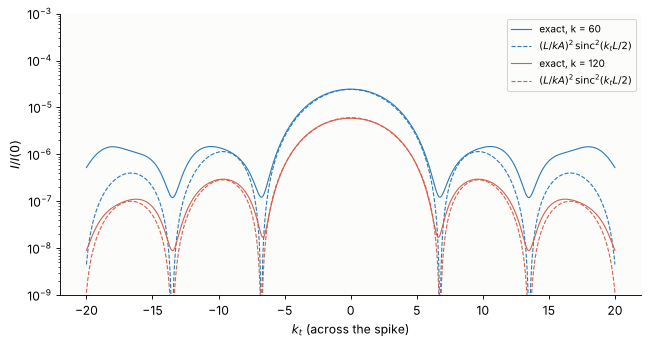

edge length L = 0.930, first zero across the spike at k_t = 2 pi/L = 6.8


In [8]:
# across a spike at k = 60: the streak is as wide as the diffraction pattern of the edge length, 2 pi/L
n_b = 7
h = ph.iris_apothem(n_b, A); v = ph.iris(n_b, h); L = ph.iris_edge_length(n_b, h)
kt = np.linspace(-20, 20, 801)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for k0, col in ((60, BLUE), (120, RED)):
    I = np.mean([abs(ph.polygon_transform(v, k0 + d, kt)/A)**2 for d in np.linspace(-2, 2, 9)], axis=0)
    ax.semilogy(kt, I, color=col, lw=1.0, label="exact, k = {}".format(k0))
    ax.semilogy(kt, ph.edge_spike(k0, L, A)*np.sinc(kt*L/(2*np.pi))**2, color=col, ls="--", lw=1.0,
                label=r"$(L/kA)^2\,\mathrm{sinc}^2(k_t L/2)$")
ax.set_xlabel(r"$k_t$ (across the spike)"); ax.set_ylabel(r"$I/I(0)$"); ax.legend(fontsize=9)
ax.set_ylim(1e-9, 1e-3)
plt.show()
print("edge length L = {:.3f}, first zero across the spike at k_t = 2 pi/L = {:.1f}".format(L, 2*np.pi/L))

Do the spikes take light away from the core? They do not. Far from the
core, each length of edge sends out the same power whatever its shape. The
fraction of the power that falls outside $k$ is

$$1 - \mathrm{EE}(k) \approx \frac{P}{\pi A k}$$

for an opening of perimeter $P$ and area $A$ (`ph.power_outside()`). For
the circle that is the familiar tail $2/(\pi kR)$ of the encircled energy
of the Airy pattern. A polygon bunches this power into spikes and a circle
spreads it into rings, but the amount is the same, up to the few percent by
which the perimeter of a polygon exceeds that of a circle of the same area.
The cell below integrates the exact patterns over the annulus $10 < k < 300$:

In [9]:
# power outside k: the same for any opening of the same perimeter and area
kr = np.linspace(10, 300, 1200)
th = np.linspace(0, 2*np.pi, 2880, endpoint=False)
K, TH = np.meshgrid(kr, th, indexing="ij")
dk, dth = kr[1] - kr[0], th[1] - th[0]
print("opening           P/(pi A)     power in 10 < k < 300:  computed   P/(pi A) (1/10 - 1/300)")
for n_b in (5, 7, 8):
    h = ph.iris_apothem(n_b, A); v = ph.iris(n_b, h)
    P = ph.polygon_perimeter(v)
    I = abs(ph.polygon_transform(v, K*np.cos(TH), K*np.sin(TH))/A)**2
    frac = A/(4*np.pi**2)*np.sum(I*K)*dk*dth
    print("{} straight blades   {:.4f}                            {:.5f}     {:.5f}".format(
        n_b, P/(np.pi*A), frac, ph.power_outside(10, P, A) - ph.power_outside(300, P, A)))
# circle of radius 1: 1 - encircled energy of the Airy pattern = J0(kR)^2 + J1(kR)^2
frac = (j0(10)**2 + j1(10)**2) - (j0(300)**2 + j1(300)**2)
print("circle             {:.4f}                            {:.5f}     {:.5f}".format(
    2/np.pi, frac, ph.power_outside(10, 2*np.pi, A) - ph.power_outside(300, 2*np.pi, A)))

opening           P/(pi A)     power in 10 < k < 300:  computed   P/(pi A) (1/10 - 1/300)


5 straight blades   0.6846                            0.06684     0.06618


7 straight blades   0.6595                            0.06200     0.06375


8 straight blades   0.6538                            0.06201     0.06320
circle             0.6366                            0.06025     0.06154


The integrals agree with $P/\pi A\,(1/k_1 - 1/k_2)$ to within 3 %. The
remaining difference is the core, where the asymptotic law does not hold
yet. Five blades put 8 % more light into the wings than a circle, eight
blades 3 % more. The striking look of a star comes from where the light
goes, not from how much there is.

## 3. Rounded blades

Many modern lenses have blades with curved edges, chosen so that the
opening is round near full aperture and the out-of-focus highlights stay
round (notebook 90). Each blade edge is an arc of radius $\rho$. The opening
is the intersection of $n$ disks of radius $\rho$, centred a distance
$\rho - h$ behind each edge (`ph.iris(n, h, rho)`). It is a circle for
$h = \rho$, at the opening the blades are made for, and becomes more and
more polygonal as the iris closes ($h < \rho$).

A curved edge has no single normal. Its normals span an angle $L/\rho$, so
it streaks light into a fan of that width. Near the middle of the edge, the
edge integral has the phase of the arc's sagitta, $k t^2/2\rho$, and
becomes a Fresnel integral (`ph.curved_edge_spike()`):

$$F \approx \frac{1}{k}\int_{-L/2}^{L/2} e^{-ikt^2/2\rho}\,dt \;\to\; \begin{cases} L/k, & k \ll k_c \quad\text{(a straight edge)}\\ \sqrt{2\pi\rho/k}\,/k, & k \gg k_c \quad\text{(stationary phase)}\end{cases}$$

The two limits meet at $k_c = 2\pi\rho/L^2$ (`ph.rounded_edge_crossover()`).
Up to there a rounded edge makes a spike just like a straight one; beyond
it, the spike spreads over the fan and falls as $1/k^3$.

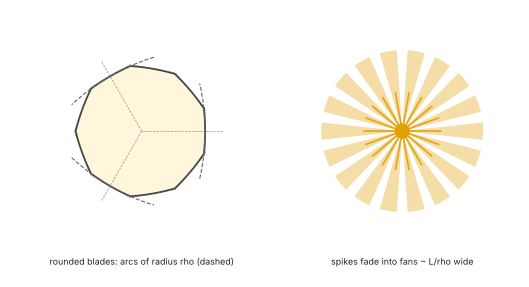

In [10]:
fig, ax = plt.subplots(figsize=(12, 4.4))
sketch.rounded_iris(ax)
plt.show()

rho = 12.0: h = 0.981, L = 0.710, k_c = 2 pi rho/L^2 =  149.4 (r_c =  47.6 lambda N); exact/model for k > 3 k_c: 0.99


rho =  4.0: h = 0.985, L = 0.705, k_c = 2 pi rho/L^2 =   50.5 (r_c =  16.1 lambda N); exact/model for k > 3 k_c: 0.99


rho =  2.0: h = 0.990, L = 0.698, k_c = 2 pi rho/L^2 =   25.8 (r_c =   8.2 lambda N); exact/model for k > 3 k_c: 1.04


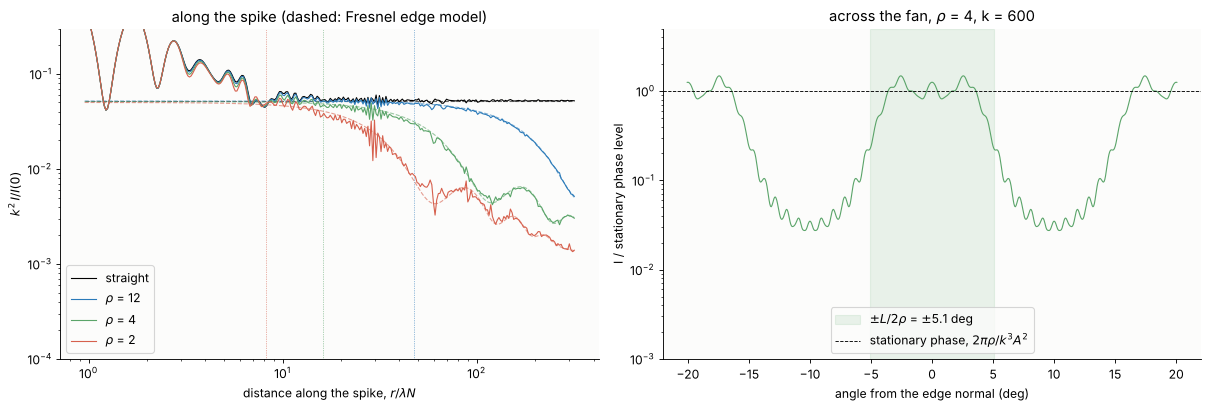

fan of rho = 4 at k = 600: mean level inside 0.8 x L/(2 rho) = 1.06 of the stationary phase value


In [11]:
# 9 blades, the same area, blade radius rho from straight to nearly round
n_b = 9
kk = np.geomspace(3, 1000, 300)
band = np.linspace(0.9, 1.1, 7)
fig, ax = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
rounded = {}
for rho, col in ((np.inf, "k"), (12.0, BLUE), (4.0, GREEN), (2.0, RED)):
    h = ph.iris_apothem(n_b, A, rho)
    v = ph.iris(n_b, h, rho, n_arc=400)
    L = ph.iris_edge_length(n_b, h, rho)
    KB = kk[:, None]*band                                      # average over a band around each k
    I = np.mean(abs(ph.polygon_transform(v, KB, 0*KB)/A)**2, axis=1)
    model = np.mean(ph.curved_edge_spike(KB, L, rho, A), axis=1)
    rounded[rho] = (h, L, v)
    lab = "straight" if not np.isfinite(rho) else r"$\rho$ = {:g}".format(rho)
    ax[0].loglog(kk/np.pi, I*kk**2, color=col, lw=1.0, label=lab)
    ax[0].loglog(kk/np.pi, model*kk**2, color=col, lw=1.0, ls="--", alpha=0.6)
    if np.isfinite(rho):
        kc = ph.rounded_edge_crossover(L, rho)
        ax[0].axvline(kc/np.pi, color=col, lw=0.6, ls=":")
        sel = (kk > 3*kc) & (kk < 1000)
        print("rho = {:4.1f}: h = {:.3f}, L = {:.3f}, k_c = 2 pi rho/L^2 = {:6.1f} (r_c = {:5.1f} lambda N); "
              "exact/model for k > 3 k_c: {:.2f}".format(rho, h, L, kc, kc/np.pi, np.mean(I[sel]/model[sel])))
ax[0].set_xlabel(r"distance along the spike, $r/\lambda N$"); ax[0].set_ylabel(r"$k^2\,I/I(0)$")
ax[0].set_ylim(1e-4, 0.3); ax[0].legend(); ax[0].set_title("along the spike (dashed: Fresnel edge model)")

# across: the fan at k = 600 for rho = 4
rho = 4.0
h, L, v = rounded[rho]
k0 = 600.0
beta = np.linspace(-0.35, 0.35, 701)
KD = k0 + np.linspace(-3, 3, 5)[:, None]
I = np.mean(abs(ph.polygon_transform(v, KD*np.cos(beta), KD*np.sin(beta))/A)**2, axis=0)
ax[1].semilogy(np.degrees(beta), I/(2*np.pi*rho/(k0**3*A**2)), color=GREEN, lw=1.0)
ax[1].axvspan(-np.degrees(L/rho/2), np.degrees(L/rho/2), color=GREEN, alpha=0.12,
              label=r"$\pm L/2\rho$ = $\pm${:.1f} deg".format(np.degrees(L/rho/2)))
ax[1].axhline(1.0, color="k", ls="--", lw=0.8, label=r"stationary phase, $2\pi\rho/k^3A^2$")
ax[1].set_xlabel("angle from the edge normal (deg)"); ax[1].set_ylabel("I / stationary phase level")
ax[1].set_title(r"across the fan, $\rho$ = 4, k = 600"); ax[1].legend(loc="lower center"); ax[1].set_ylim(1e-3, 5)
plt.show()
inside = np.abs(beta) < 0.8*L/rho/2
print("fan of rho = 4 at k = 600: mean level inside 0.8 x L/(2 rho) = {:.2f} of the stationary phase value".format(
    np.mean(I[inside])/(2*np.pi*rho/(k0**3*A**2))))

Along the spike (left), the exact patterns of nine rounded blades follow the
straight edge's $(L/A)^2$ up to $k_c$ (dotted lines), then bend down to the
$1/k^3$ of the stationary phase. The Fresnel model (dashed) agrees with the
exact transform within 4 % beyond $3k_c$, and it also shows the wiggles at
the transition. Across (right), well beyond $k_c$, the light fills a fan
$\pm L/2\rho$ wide at the stationary phase level, 1.06 times
$2\pi\rho/k^3A^2$ on average, and falls off sharply outside it. The bumps at
$\pm 20°$ are the fans of the neighbouring edges.

The power in the fan is the same as in the spike of a straight edge.
Integrated across, the fan carries $2\pi\rho/k^3 \cdot kL/\rho = 2\pi L/k^2$,
the same as the spike's $L^2/k^2 \cdot 2\pi/L$. A rounded blade spreads the
streak of its edge sideways, consistent with section 2's rule that the
amount of edge light depends only on the edge length.

## 4. The F-number

Take a 24 mm wide angle lens with nine rounded blades that make a round
opening at f/2.8, so $\rho = f/5.6 = 4.29$ mm. For comparison take the same
lens with seven straight blades. The Sun's image is a disk of radius
$a = f\tan(0.267°) = 112$ µm.

Stopping down changes two things at once:

1. **The shape of the iris.** At a smaller opening the arcs are flat
   relative to the opening. The fan of each edge, $L/\rho$, narrows from
   28° at f/4 to 5° at f/22, and the crossover
   $r_c = \lambda f\rho/L^2 \propto N^2$ moves outward.
2. **The brightness of the rays.** The spike of a straight edge is a line
   whose irradiance, integrated across, is $L\lambda f/(4\pi^2 r^2 A)$ per
   unit power. Convolved with the Sun's disk, it is spread over a band
   $2a$ wide, and relative to the irradiance of the disk itself,

   $$\frac{E_{\rm spike}(r)}{E_\odot} = \frac{a\,L\,\lambda f}{2\pi^2 r^2 A} \;\propto\; \frac{a\,\lambda N}{r^2},$$

   because $L/A \propto 1/D = N/f$. Stopping down makes the rays brighter
   relative to the Sun.

How far a ray reaches in a photo depends on how much the Sun is
overexposed. The Sun's luminance is about $1.6\cdot 10^9$ cd/m². A white
page in full sunlight (about $10^5$ lx) is about $3\cdot 10^4$ cd/m². A
normal exposure puts that white about one stop below clipping, so the
Sun's disk is at about $S = 10^5$ times the clipping level, 17 stops over.
A ray is visible where $S\,E_{\rm spike}/E_\odot > 1$:

$$r_{\rm vis} = \sqrt{\frac{S\,a\,L\,\lambda f}{2\pi^2 A}} \;\propto\; \sqrt{S\,\lambda N f}.$$

So the rays grow as $\sqrt N$ (twice as long from f/4 to f/16), are longer
in red light than in blue, and for an even number of blades are $\sqrt 2$
longer than the one-edge formula, because two edges share each spike.

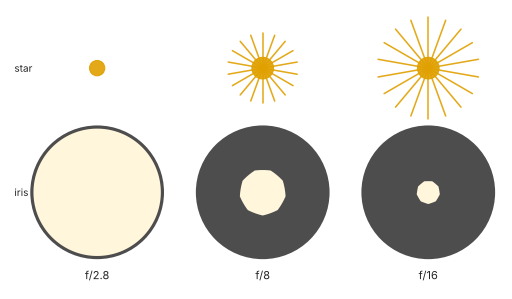

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.6))
sketch.iris_stop_down(ax)
plt.show()

Sun image radius a = 112 um; blade radius rho = 4.29 mm
 f/N    D_eq (mm)  h (mm)   L (mm)   fan L/rho (deg)  r_c = lambda f rho/L^2 (um)  r_c/(lambda N)
  4.0     6.000     2.982    2.077       27.8                    13                  6.0
  5.6     4.286     2.121    1.496       20.0                    25                  8.2
  8.0     3.000     1.480    1.054       14.1                    51                 11.6
 11.0     2.182     1.074    0.769       10.3                    96                 15.8
 16.0     1.500     0.737    0.531        7.1                   201                 22.8
 22.0     1.091     0.536    0.387        5.2                   378                 31.3


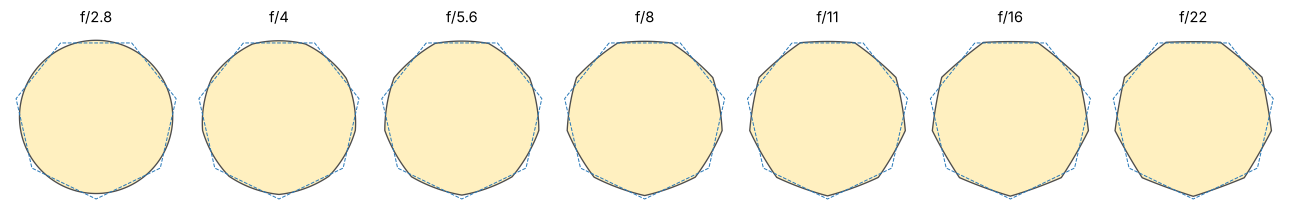

In [13]:
# a 24 mm lens with 9 rounded blades, round at f/2.8 (rho = f/5.6), and one with 7 straight blades
f, lam = 24.0, 550e-6                          # mm
rho_lens = f/(2*2.8)
a_sun = f*np.tan(ph.SUN_RADIUS)
F_NUMBERS = [2.8, 4, 5.6, 8, 11, 16, 22]
print("Sun image radius a = {:.0f} um; blade radius rho = {:.2f} mm".format(1e3*a_sun, rho_lens))
print(" f/N    D_eq (mm)  h (mm)   L (mm)   fan L/rho (deg)  r_c = lambda f rho/L^2 (um)  r_c/(lambda N)")
geom = {}
for N in F_NUMBERS[1:]:
    A_N = np.pi*(f/(2*N))**2
    h = ph.iris_apothem(9, A_N, rho_lens)
    L = ph.iris_edge_length(9, h, rho_lens)
    r_c = lam*f*rho_lens/L**2
    geom[N] = (h, L)
    print("{:5.1f}   {:7.3f}   {:7.3f}  {:7.3f}     {:6.1f}              {:8.0f}                {:5.1f}".format(
        N, f/N, h, L, np.degrees(L/rho_lens), 1e3*r_c, r_c/(lam*N)))

fig, ax = plt.subplots(1, len(F_NUMBERS), figsize=(16, 2.9), layout="constrained")
for a, N in zip(ax, F_NUMBERS):
    A_N = np.pi*(f/(2*N))**2
    if N == 2.8:
        v = ph.iris(9, rho_lens, rho_lens, rotation=np.pi/2)
    else:
        v = ph.iris(9, ph.iris_apothem(9, A_N, rho_lens), rho_lens, rotation=np.pi/2)
    vs = ph.iris(7, ph.iris_apothem(7, A_N), rotation=np.pi/2)
    a.fill(*np.r_[v, v[:1]].T, color="#fff0c0", ec="0.3", lw=1.2)
    a.plot(*np.r_[vs, vs[:1]].T, color=BLUE, lw=0.9, ls="--")
    a.set_aspect("equal"); a.axis("off"); a.set_title("f/{:g}".format(N))
    s = 1.15*f/(2*N); a.set_xlim(-s, s); a.set_ylim(-s, s)
plt.show()

The table and the outlines (rounded nine-blade iris filled; seven straight
blades dashed) show the iris closing from a circle at f/2.8 to a nonagon
with only slightly bulged sides at f/22. At f/16, $r_c$ is 0.2 mm, about two
radii of the Sun's image. Beyond that the rays of the rounded iris are fans,
but only 7° wide.

The next cell renders the Sun at 550 nm for both irises at f/5.6 to f/22
(`ph.sunstar()`). It convolves the diffraction pattern with the Sun's disk
and with 4 µm pixels, and reads the irradiance along the ray that is
normal to an edge:

10 images in 35 s
 f/N   7 straight: r_vis (mm)  theory sqrt(S a L lambda f/(2 pi^2 A))   9 rounded: r_vis (mm)
  5.6         1.04                      1.02                                  0.75
  8.0         1.23                      1.21                                  0.94
 11.0         1.43                      1.42                                  1.13
 16.0         1.71                      1.72                                  1.39
 22.0         2.02                      2.01                                  1.64


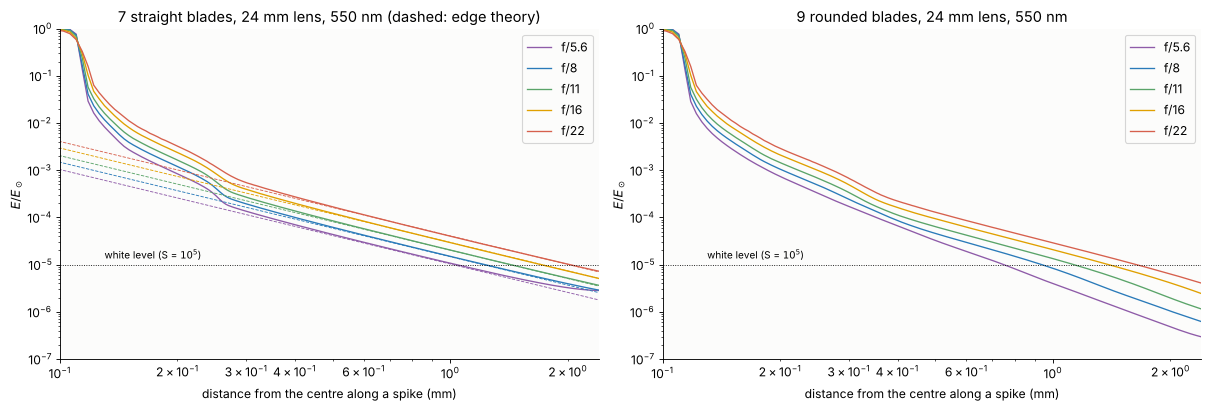

7 straight blades, spike/theory at r = 0.5, 1.0, 1.5 mm:
  f/5.6  1.05 1.04 1.10
  f/8    1.05 1.02 1.03
  f/11   1.04 1.00 1.01
  f/16   1.04 0.99 0.99
  f/22   1.03 0.99 0.99


In [14]:
# the sunstar of one wavelength at several F-numbers: spike irradiance relative to the Sun's disk
S = 1e5                      # the Sun's disk is about 10^5 times the white level (see text)
hw = 2.4
spike_runs = {}
t0 = time.time()
for kind, n_b, r_b in (("7 straight", 7, np.inf), ("9 rounded", 9, rho_lens)):
    for N in (5.6, 8, 11, 16, 22):
        x, E = ph.sunstar(n_b, N, lam, focal_length=f, blade_radius=r_b, rotation=0.0, half_width=hw)
        spike_runs[(kind, N)] = E[0]
print("{} images in {:.0f} s".format(len(spike_runs), time.time() - t0))
c = len(x)//2
r = x[c:]

def straight_theory(N, r):
    A_N = np.pi*(f/(2*N))**2
    L = ph.iris_edge_length(7, ph.iris_apothem(7, A_N))
    return a_sun*L*lam*f/(2*np.pi**2*r**2*A_N)

fig, ax = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
cols = dict(zip((5.6, 8, 11, 16, 22), (PURPLE, BLUE, GREEN, ORANGE, RED)))
print(" f/N   7 straight: r_vis (mm)  theory sqrt(S a L lambda f/(2 pi^2 A))   9 rounded: r_vis (mm)")
for N in (5.6, 8, 11, 16, 22):
    rows = {}
    for a, kind in zip(ax, ("7 straight", "9 rounded")):
        E = spike_runs[(kind, N)]
        prof = E[c, c:]                                  # along +x: the normal of the first edge
        a.loglog(r, prof, color=cols[N], lw=1.2, label="f/{:g}".format(N))
        if kind == "7 straight":
            a.loglog(r, straight_theory(N, r), color=cols[N], ls="--", lw=0.8)
        above = np.nonzero((r > 2*a_sun) & (prof*S < 1))[0]
        rows[kind] = r[above[0]] if len(above) else np.nan
    A_N = np.pi*(f/(2*N))**2
    L = ph.iris_edge_length(7, ph.iris_apothem(7, A_N))
    r_th = np.sqrt(S*a_sun*L*lam*f/(2*np.pi**2*A_N))
    print("{:5.1f}        {:5.2f}                     {:5.2f}                                 {:5.2f}".format(
        N, rows["7 straight"], r_th, rows["9 rounded"]))
for a, kind in zip(ax, ("7 straight", "9 rounded")):
    a.axhline(1/S, color="k", lw=0.8, ls=":")
    a.text(0.13, 1.3/S, "white level (S = $10^5$)", fontsize=9)
    a.set_xlim(0.1, hw); a.set_ylim(1e-7, 1)
    a.set_xlabel("distance from the centre along a spike (mm)"); a.set_ylabel(r"$E/E_\odot$")
    a.set_title(kind + " blades, 24 mm lens, 550 nm" + (" (dashed: edge theory)" if kind == "7 straight" else ""))
    a.legend()
plt.show()

rr = np.array([0.5, 1.0, 1.5])
print("7 straight blades, spike/theory at r = 0.5, 1.0, 1.5 mm:")
for N in (5.6, 8, 11, 16, 22):
    E = spike_runs[("7 straight", N)]
    i = np.searchsorted(r, rr)
    print("  f/{:<4g}".format(N), " ".join("{:.2f}".format(q) for q in E[c, c:][i]/straight_theory(N, r[i])))

For the seven straight blades, the rendered rays agree with the edge theory
(dashed) to within 5 % from 0.5 mm out to 1.5 mm at every F-number (10 %
at the edge of the f/5.6 image, where the periodic FFT folds the tail
back). Measured from the images, the visible length agrees with
$r_{\rm vis} = \sqrt{S a L\lambda f/2\pi^2A}$ to within 0.03 mm, growing
from 1.0 mm at f/5.6 to 2.0 mm at f/22, $\propto\sqrt N$.

The rounded blades give shorter rays, 0.75 to 1.64 mm. Part of the
difference is just nine blades instead of seven, since nine edges of the
same area are shorter. The rest is the fan. Near the core it is wider than
the Sun's image and its light is spread out. At f/16 and beyond it is
narrower, and the star looks almost like that of straight blades. A simple
measure shows this: the brightest point on a circle of 1 mm around the
Sun, divided by the mean around that circle:

In [15]:
# how star-like is the rounded iris? spike over the mean along the circle at r = 1 mm
print(" f/N    7 straight: spike/mean    9 rounded: spike/mean")
th = np.linspace(0, 2*np.pi, 3600, endpoint=False)
contrast = {}
for N in (5.6, 8, 11, 16, 22):
    vals = []
    for kind in ("7 straight", "9 rounded"):
        E = spike_runs[(kind, N)]
        xs = 1.0*np.cos(th); ys = 1.0*np.sin(th)
        ring = map_coordinates(E, [(ys - x[0])/(x[1] - x[0]), (xs - x[0])/(x[1] - x[0])], order=1)
        vals.append(ring.max()/ring.mean())
    contrast[N] = vals
    print("{:5.1f}        {:6.1f}                  {:6.1f}".format(N, *vals))

 f/N    7 straight: spike/mean    9 rounded: spike/mean
  5.6           2.6                     1.0
  8.0           2.6                     1.5
 11.0           2.5                     1.7
 16.0           2.5                     1.8
 22.0           2.5                     1.8


The straight iris gives the same contrast (2.5) at every F-number, since
its shape does not change. The rounded iris gives no star at f/5.6 (1.0:
the fans of 20° overlap all around), a weak one at f/8 (1.5), and a clear
star from f/11 on (1.7 to 1.8, against 2.5 for straight blades). That matches what
photographers report: lenses with rounded blades make soft or no sunstars
near full aperture and proper ones when stopped down.

## 5. Rendered sunstars

The last step is colour. The Sun's spectrum is a 5778 K black body, sampled
at 7 wavelengths from 430 to 670 nm. One FFT of the opening serves all of
them, because the pattern in $k$ is the same and only its scale in the
image, $r = k\lambda f/2\pi$, grows with the wavelength. Each wavelength is
convolved with the Sun's disk and the pixels and converted to CIE XYZ and
sRGB (`pyoptics.colour`), white balanced on the Sun. The disk is exposed
at $S = 10^5$ times the white level, with a film-like shoulder
$1 - e^{-x}$ so that the clipped regions are not flat.

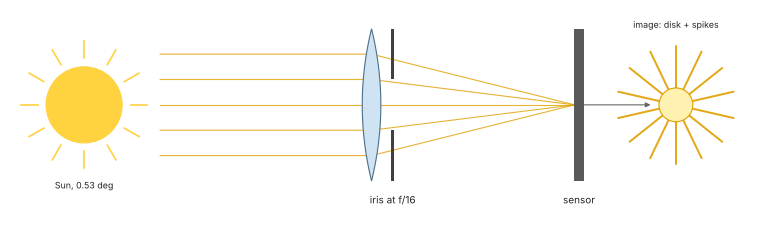

In [16]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.sunstar_scene(ax)
plt.show()

rendered 6 images x 7 wavelengths in 35 s


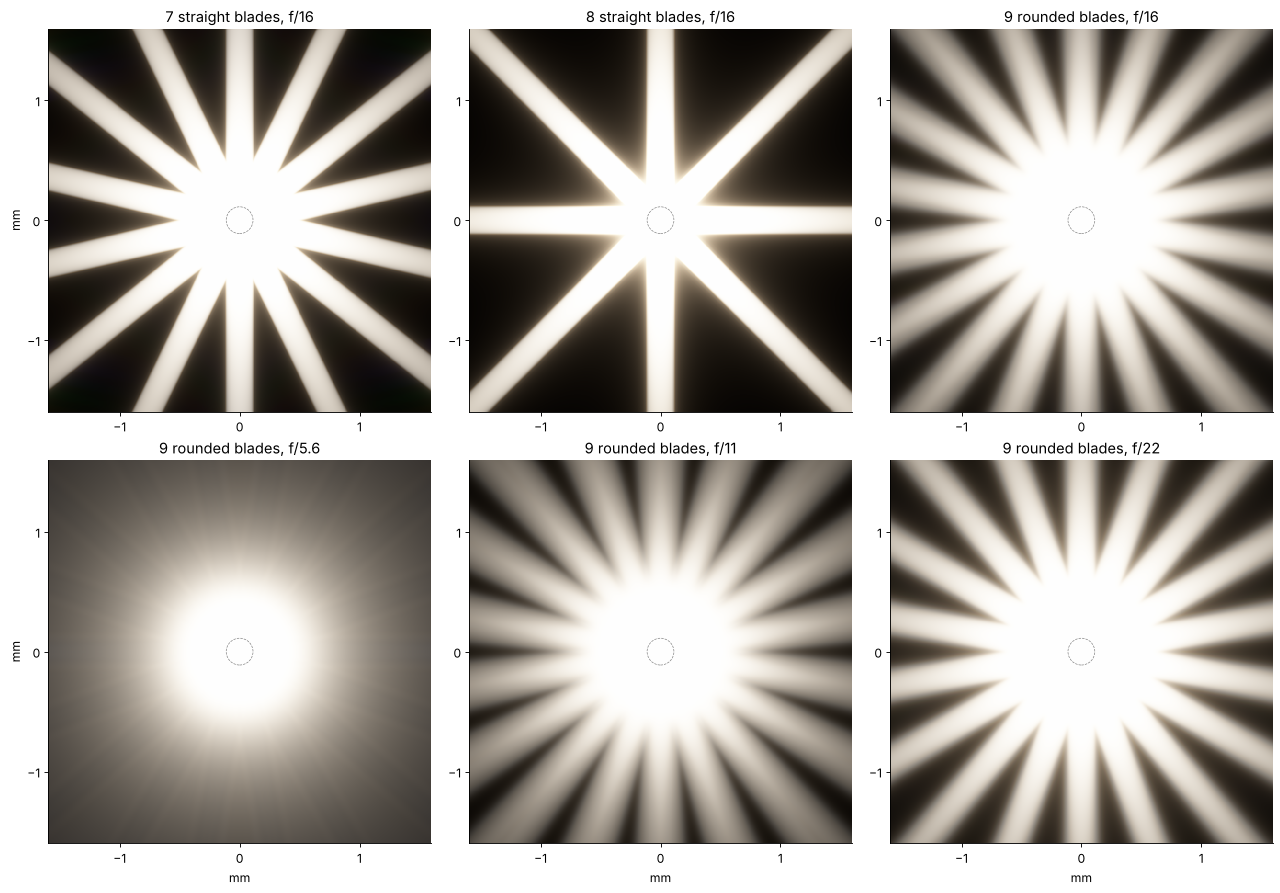

In [17]:
# colour renders: Sun (black body 5778 K), 7 wavelengths, 24 mm lens, 4 um pixels
lam_nm = np.linspace(430, 670, 7)
w = colour.planck(lam_nm, 5778.0)
cmf = colour.cie_xyz(lam_nm)                                  # (3, L)
white = colour.xyz_to_linear_srgb((cmf*w).sum(axis=1))

def to_srgb(E, S=1e5):
    """Spectral stack (L, ny, nx), relative to the Sun's disk, to sRGB: white balanced on the
    Sun, the disk at S times the white level, a film-like shoulder 1 - exp(-x)."""
    XYZ = np.tensordot(cmf*w, E, axes=(1, 0))
    rgb = colour.xyz_to_linear_srgb(np.moveaxis(XYZ, 0, -1))/white
    return colour.srgb_gamma(1 - np.exp(-np.clip(S*rgb, 0, None)))

renders = {}
t0 = time.time()
for key, n_b, N, r_b in (("7 straight blades, f/16", 7, 16, np.inf), ("8 straight blades, f/16", 8, 16, np.inf),
                         ("9 rounded blades, f/16", 9, 16, rho_lens), ("9 rounded blades, f/5.6", 9, 5.6, rho_lens),
                         ("9 rounded blades, f/11", 9, 11, rho_lens), ("9 rounded blades, f/22", 9, 22, rho_lens)):
    x, E = ph.sunstar(n_b, N, lam_nm*1e-6, focal_length=f, blade_radius=r_b, rotation=np.pi/2, half_width=1.6)
    renders[key] = to_srgb(E)
print("rendered {} images x {} wavelengths in {:.0f} s".format(len(renders), len(lam_nm), time.time() - t0))

fig, ax = plt.subplots(2, 3, figsize=(16, 11), layout="constrained")
for a, (key, img) in zip(ax.ravel(), renders.items()):
    a.imshow(img, extent=[x[0], x[-1], x[0], x[-1]], origin="lower", interpolation="nearest")
    a.set_title(key); a.set_xticks([-1, 0, 1]); a.set_yticks([-1, 0, 1])
    a.add_patch(plt.Circle((0, 0), a_sun, fill=False, ec="0.5", lw=0.6, ls="--"))
for a in ax[:, 0]:
    a.set_ylabel("mm")
for a in ax[1]:
    a.set_xlabel("mm")
plt.show()

Top row, all at f/16: seven straight blades give 14 rays. Eight straight
blades give 8, longer and brighter, because two edges feed each ray. Nine
rounded blades give 18 rays, shorter and softer, with more glow between
them. Bottom row, the rounded iris stopped down: at f/5.6
there is only a glow, the fans merging around the Sun; at f/11 a star
appears, and at f/22 it is nearly as crisp as that of straight blades.

The dashed circle is the geometric image of the Sun. Everything outside it
is diffraction. The rays are about as wide as the Sun's image, because each
is a copy of the disk smeared along a line. Their tips are warm, because the
rays of red light reach $\sqrt{670/430} = 1.25$ times as far as blue ones.
The fringes along the rays of an even iris, about $\lambda N \approx 9$ µm
apart, are averaged away by the Sun's 0.22 mm disk. A street lamp, which is
nearly a point, would show them.

Real lenses add their own effects. Aberrations blur the core but hardly the
far rays, which come from the edges. Dust and scratches add a diffuse glow,
and the reflections between the lens surfaces add ghosts and veiling flare.

## Summary

- The image of a distant bright point is the Fraunhofer pattern of the
  iris, $|F(\mathbf k)|^2$. For a polygon, $F$ is an exact sum over the
  edges, and the FFT of the antialiased opening matches it to a few percent.
- Each straight edge streaks light along its normal in both directions
  with amplitude $L/k$, an intensity that falls as $1/r^2$. This gives 2n
  spikes for an odd number of blades and n for an even number. The spikes
  of an even iris carry the fringes of two parallel edges and are twice as
  bright.
- Spikes take nothing from the core. The power outside $k$ is $P/\pi A k$
  for any shape, and a polygon only bunches it into lines.
- A rounded blade edge (radius $\rho$, chord $L$) behaves like a straight
  one up to $k_c = 2\pi\rho/L^2$. Beyond that its spike becomes a fan
  $L/\rho$ wide that falls as $1/r^3$ but carries the same power.
- For the Sun, a spike relative to the Sun's disk is
  $aL\lambda f/(2\pi^2r^2A) \propto a\lambda N/r^2$, and its visible
  length is $r_{\rm vis} = \sqrt{SaL\lambda f/2\pi^2A} \propto \sqrt{S\lambda N f}$,
  confirmed by the renders to within a few percent. Stopping down makes the
  star longer. It also makes the star sharper, because the fans of rounded
  blades narrow below the Sun's image: no star at f/5.6, a proper one from
  f/11.

In [18]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 86 s


## References

- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University
  Press (1999), section 8.5 (Fraunhofer diffraction at apertures of various
  forms).
- J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed., Roberts (2005),
  chapters 4 and 6.
- S.-W. Lee and R. Mittra, "Fourier transform of a polygonal shape function
  and its application in electromagnetics", IEEE Trans. Antennas Propag.
  31, 99–103 (1983).
- J. B. Keller, "Geometrical theory of diffraction", J. Opt. Soc. Am. 52,
  116–130 (1962), on edge waves.
- J. E. Harvey and C. Ftaclas, "Diffraction effects of telescope secondary
  mirror spiders on various image-quality criteria", Appl. Opt. 34,
  6337–6349 (1995).
- C. Wyman, P.-P. Sloan and P. Shirley, "Simple analytic approximations to
  the CIE XYZ color matching functions", J. Comput. Graph. Tech. 2, 1–11
  (2013), as used in `pyoptics.colour`.